# Explainers: the ceiling, and the contact-only tree

Ideas from the other notebooks that are easier to see than to describe:

1. **The ceiling**: why there's a hard upper limit on how well *any* model can do with a fixed set of yes/no answers, and how it's calculated.
2. **The contact-only model**: what the "model" actually is when it's given a single question, and why its probabilities can be wrong while its auROC is right.
3. **The three LightGBMs** in `alternative-modelling.ipynb`, and how they differ.
4. **How the datasets differ**, and how confident we'd be deploying the paper's model.

Everything uses the Israeli data and the paper's split (train 22–31 Mar 2020, test 1–7 Apr), as in the other notebooks.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve
from sklearn.tree import DecisionTreeClassifier, plot_tree

import symptompred as sp

warnings.filterwarnings("ignore")
BLUE, ORANGE, AQUA, GREY, RED, INK = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#e34948", "#0b0b0b"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold",
})

israel = sp.datasets.israel.load(drop_unknown_sex=True)
train, test = sp.date_split(israel, sp.datasets.israel.PAPER_TRAIN, sp.datasets.israel.PAPER_TEST)
print(f"Test week: {len(test):,} people, {test.y.sum():,} positive ({test.y.mean():.1%})")

Test week: 47,401 people, 3,624 positive (7.6%)


---
# 1. The ceiling

**The short version:** group everyone by their answers, then sort the groups from most to least likely to be positive. A model can only get that order right or wrong. The ceiling is what you'd score if you got it perfectly right, and nobody can separate the people *within* a group.

The rest of this section is a worked example of that sentence, one step at a time.

## 1.1 People with the same answers are indistinguishable

The model sees nothing but the answers. Everyone who gave exactly the same answers gets exactly the same score. So the test week splits into **cells**: groups of people with identical answers.

With just one question, contact with a confirmed case, there are two cells:

In [2]:
def cell_table(df, features):
    # One row per combination of answers: how many people, how many positive, and the positive rate
    t = df.groupby(features, dropna=False)["y"].agg(people="size", positives="sum", rate="mean")
    return t.sort_values("rate", ascending=False)

cell_table(test, ["contact"]).rename(index={1.0: "yes", 0.0: "no"}).style.format({"rate": "{:.1%}", "people": "{:,}", "positives": "{:,}"})

,people,positives,rate
contact,,,
yes,"2,476","1,719",69.4%
no,"44,925","1,905",4.2%


## 1.2 auROC only measures the *order*

auROC is the chance that a randomly chosen positive person gets a higher score than a randomly chosen negative person. Ties count as half.

- A positive and a negative in **different** cells: the model gets the pair right if it ranks their cells in the right order.
- A positive and a negative in the **same** cell: always a tie, whatever the model does. No model can separate them, because they gave identical answers.

So the only real choice a model makes is the **order of the cells**. The best possible order puts the cells in descending order of their actual positive rate. Any other order swaps a higher-rate cell below a lower-rate one and loses pairs.

**The ceiling is the auROC of that perfect order.** It's calculated from the test week's own results, so it isn't a fair model: it's the limit no model using these answers can beat. `sp.oracle_ceiling` does exactly this.

With two cells there's only one sensible order (contact above no contact), so every sensible model scores the same. With a single cut-off, auROC is simply the average of sensitivity and specificity:

In [3]:
flagged, positive = test.contact == 1, test.y == 1
sens = (flagged & positive).sum() / positive.sum()
spec = (~flagged & ~positive).sum() / (~positive).sum()
print(f"Contact as a rule: sensitivity {sens:.3f}, specificity {spec:.3f}")
print(f"(sensitivity + specificity) / 2 = {(sens + spec) / 2:.4f}")
print(f"Ceiling for contact only:         {sp.oracle_ceiling(test, ['contact'])['auroc']:.4f}")
print(f"Contact-only LightGBM (alternative-data 4.6): "
      f"{sp.SymptomModel(features=['contact']).fit(train).evaluate(test, bootstrap=0)['auroc']:.4f}")

Contact as a rule: sensitivity 0.474, specificity 0.983
(sensitivity + specificity) / 2 = 0.7285
Ceiling for contact only:         0.7285


Contact-only LightGBM (alternative-data 4.6): 0.7285


With one yes/no question there's nothing for a model to be clever about: the score is fixed at 0.7285 before any model is trained.

The same "ties inside a cell" limit applies with all 8 questions. Here is the largest group of people in the test week who gave identical answers:

In [4]:
F = list(sp.CORE_FEATURES)
all8 = cell_table(test, F)
key = all8.people.idxmax()
big = all8.loc[key]
print(f"{int(big.people):,} people answered: " + ", ".join(f"{f} = {'yes' if v == 1 else 'no'}" for f, v in zip(F, key)))
print(f"{int(big.positives)} of them tested positive ({big.rate:.1%}).")
print("Every model using these 8 answers must give all of them the same score, so none can pick out those "
      f"{int(big.positives)} people.")

16,716 people answered: cough = no, fever = no, sore_throat = no, shortness_of_breath = no, headache = no, age_60 = no, male = yes, contact = no
293 of them tested positive (1.8%).
Every model using these 8 answers must give all of them the same score, so none can pick out those 293 people.


## 1.3 More questions split the cells and raise the ceiling

Each extra yes/no question can split every cell in two. Smaller, more specific cells can be ordered more finely, so the ceiling rises. Below, each bar is a cell (a combination of answers), sorted by its actual positive rate in the test week. The bar's **height** is the positive rate and its **width** is the number of people. Narrow cells are left unlabelled, including a few small ones where an answer was left blank. The large pale block on the right of each panel is the people who answered "no" to everything shown. In the 3-question panel that's 38,260 people with a 1.8% positive rate: a model can't pick out the 694 positives among them.

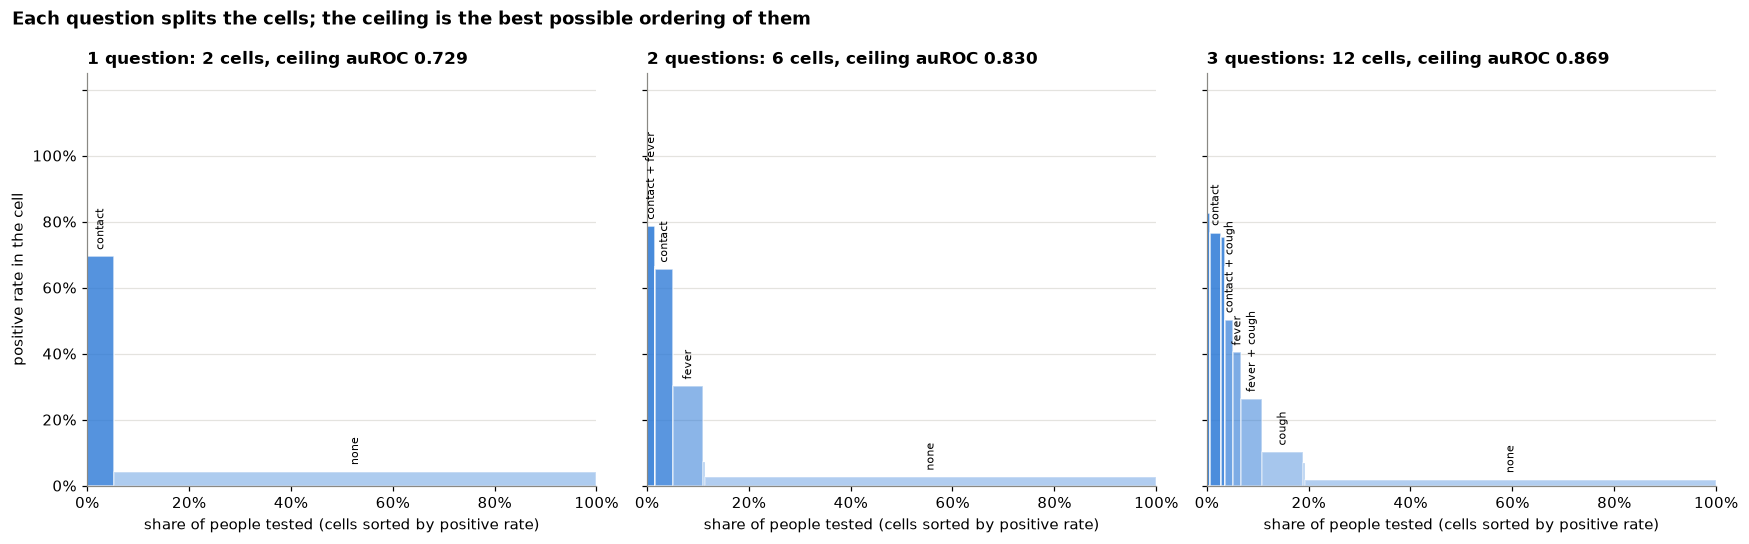

In [5]:
def label(row, features):
    yes = [f.replace("_", " ") for f, v in zip(features, row) if v == 1]
    blank = [f.replace("_", " ") for f, v in zip(features, row) if pd.isna(v)]
    text = " + ".join(yes) if yes else "none"
    return text + (f" ({', '.join(blank)} blank)" if blank else "")

def cell_bars(ax, df, features):
    t = cell_table(df, features)
    left = 0
    for key, row in t.iterrows():
        key = key if isinstance(key, tuple) else (key,)
        width = row.people / len(df)
        ax.bar(left, row.rate, width=width, align="edge", color=BLUE, alpha=0.35 + 0.65 * row.rate,
               edgecolor="white", linewidth=1)
        if width > 0.012:
            ax.text(left + width / 2, row.rate + 0.02, label(key, features), rotation=90, ha="center", va="bottom", fontsize=7.5)
        left += width
    c = sp.oracle_ceiling(df, features)
    ax.set_title(f"{len(features)} question{'s' if len(features) > 1 else ''}: {c['combinations']} cells, ceiling auROC {c['auroc']:.3f}",
                 loc="left", fontsize=11)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.25)
    ax.set_xlabel("share of people tested (cells sorted by positive rate)")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}" if v <= 1 else ""))
    ax.grid(axis="x", visible=False)

steps = [["contact"], ["contact", "fever"], ["contact", "fever", "cough"]]
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, feats in zip(axes, steps):
    cell_bars(ax, test, feats)
axes[0].set_ylabel("positive rate in the cell")
fig.suptitle("Each question splits the cells; the ceiling is the best possible ordering of them", fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
plt.show()

The same thing as ROC curves. The ceiling's ROC curve is a **staircase** with one corner per cell: the "model" walks down the sorted cells, flagging one whole cell at a time. More cells means more, finer steps that hug the top-left corner more closely.

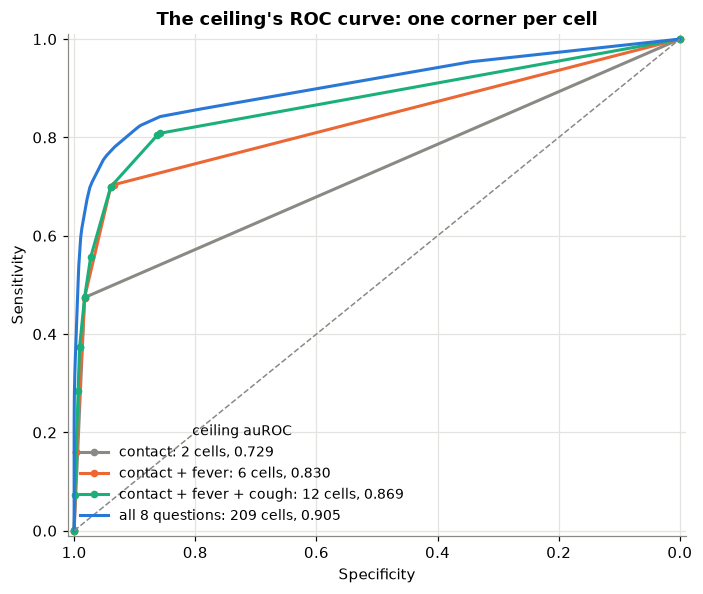

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
F = list(sp.CORE_FEATURES)
for feats, color in [(["contact"], GREY), (["contact", "fever"], ORANGE), (["contact", "fever", "cough"], AQUA), (F, BLUE)]:
    score = test.groupby(feats, dropna=False)["y"].transform("mean")  # the ceiling's "prediction" = the cell's actual rate
    fpr, tpr, _ = roc_curve(test.y, score)
    c = sp.oracle_ceiling(test, feats)
    name = "all 8 questions" if feats == F else " + ".join(feats)
    ax.plot(1 - fpr, tpr, color=color, linewidth=2, marker="o" if len(feats) < 8 else None, markersize=4,
            label=f"{name}: {c['combinations']} cells, {c['auroc']:.3f}")
ax.plot([1, 0], [0, 1], color=GREY, linestyle="--", linewidth=1)
ax.set(xlim=(1.01, -0.01), ylim=(-0.01, 1.01), xlabel="Specificity", ylabel="Sensitivity",
       title="The ceiling's ROC curve: one corner per cell")
ax.legend(frameon=False, fontsize=9, loc="lower left", title="ceiling auROC", title_fontsize=9)
plt.tight_layout()
plt.show()

The worked example as a table. "Cells" counts the combinations of yes/no answers. A few people left an answer blank, which creates a handful of extra, tiny cells, counted separately here.

In [7]:
rows = []
for feats in [["contact"], ["contact", "fever"], ["contact", "fever", "cough"], F]:
    c = sp.oracle_ceiling(test, feats)
    answered = test.dropna(subset=feats).groupby(feats).ngroups
    rows.append({"questions": "all 8" if feats == F else " + ".join(feats), "cells (yes/no answers)": answered,
                 "cells including blanks": c["combinations"], "ceiling auROC": c["auroc"], "ceiling auPRC": c["auprc"]})
pd.DataFrame(rows).set_index("questions").style.format({"ceiling auROC": "{:.3f}", "ceiling auPRC": "{:.3f}"})

,cells (yes/no answers),cells including blanks,ceiling auROC,ceiling auPRC
questions,,,,
contact,2,2,0.729,0.370
contact + fever,4,6,0.830,0.479
contact + fever + cough,8,12,0.869,0.537
all 8,200,209,0.905,0.724


## 1.4 Where real models lose: getting the order wrong

A real model has to *guess* the order from the training week. Plain logistic regression adds up one weight per answer, with no interactions, so its order is forced to be "additive". With three questions that matters. Among people without contact, fever *with* cough is lower risk than fever alone (the training week shows the same pattern), but an additive model must rank "fever + cough" above "fever". The table compares each model's order with the true order:

In [8]:
feats = ["contact", "fever", "cough"]
tr3, te3 = train.dropna(subset=feats), test.dropna(subset=feats)
additive = LogisticRegression().fit(tr3[feats], tr3.y)
t = cell_table(te3, feats)
grid = pd.DataFrame(list(t.index), columns=feats)
t["additive model's prediction"] = additive.predict_proba(grid)[:, 1]
t["true rank"] = range(1, len(t) + 1)
t["additive model's rank"] = t["additive model's prediction"].rank(ascending=False).astype(int)
t["training-week rate"] = train.groupby(feats)["y"].mean().reindex(t.index).values

def auroc_from(cell_scores):
    s = te3.set_index(feats).index.map(cell_scores)
    return sp.metrics(te3.y.values, np.asarray(s, dtype=float))["auroc"]

print(f"Ceiling (true order):                           {auroc_from(t['rate'].to_dict()):.4f}")
additive_scores = t["additive model's prediction"].to_dict()
print(f"Additive model (logistic regression):           {auroc_from(additive_scores):.4f}")
print(f"Lookup of training-week rates (order learned):  {auroc_from(t['training-week rate'].to_dict()):.4f}")
t.index = pd.MultiIndex.from_tuples([tuple("yes" if v == 1 else "no" for v in k) for k in t.index], names=feats)
t.style.format({"rate": "{:.1%}", "additive model's prediction": "{:.1%}", "training-week rate": "{:.1%}", "people": "{:,}"})\
    .apply(lambda r: ["background-color: #fde2dc" if r["true rank"] != r["additive model's rank"] else "" for _ in r], axis=1)

Ceiling (true order):                           0.8689
Additive model (logistic regression):           0.8663
Lookup of training-week rates (order learned):  0.8689


The interaction in plain numbers. Among people **without** contact:

In [9]:
no_contact = {"fever only": (1, 0), "fever and cough": (1, 1), "cough only": (0, 1)}
for week, df in [("test week", test), ("training week", train)]:
    nc = df[df.contact == 0]
    rates = {name: nc[(nc.fever == fv) & (nc.cough == cg)].y.mean() for name, (fv, cg) in no_contact.items()}
    print(f"{week:14s} " + "   ".join(f"{name}: {r:.1%}" for name, r in rates.items()))

test week      fever only: 40.5%   fever and cough: 26.4%   cough only: 10.2%
training week  fever only: 55.6%   fever and cough: 31.8%   cough only: 13.1%


Adding cough to fever *lowers* the risk, in both weeks. An additive model gives cough a positive weight (cough alone is riskier than no symptoms), so it must score "fever and cough" *above* "fever only": the wrong order.

In the table above, the highlighted rows are where the additive model's rank differs from the true rank. Simply using each cell's *training-week* rate puts the cells in exactly the true order, so it matches the ceiling, because it can represent "fever + cough is lower risk than fever alone". That's the whole story of `alternative-modelling.ipynb` in miniature: models that can capture interactions reach the ceiling, and additive ones can't.

## 1.5 Caveats when explaining the ceiling

- **It belongs to a set of features.** Add a question and it rises. Remove contact and it drops from 0.905 to 0.804. Better questions are the real lever.
- **It uses the test week's actual rates,** which no model can know in advance. Israel's cells are large, so the training week's rates are a good guide and the ceiling is nearly reachable (the best models get within 0.001 of it).
- **With many questions and few positives it's inflated.** A cell containing one person who happened to test positive counts as a "100% cell" and goes to the top, which no real model could anticipate. That's why it's a reliable bound for Israel but overstates what's possible for the US and Brazil data.

In [10]:
print(f"All 8 questions: {len(all8)} cells in the test week, {(all8.people == 1).sum()} of them containing a single person")

All 8 questions: 209 cells in the test week, 45 of them containing a single person


---
# 2. The contact-only model

In `alternative-data` 4.6, LightGBM trained on contact alone scored 0.73. Here's what that model actually is.

In [11]:
contact_model = sp.SymptomModel(features=["contact"]).fit(train)
booster = contact_model.boosters_[0]
dump = booster.dump_model()
print(f"Trees kept after early stopping: {contact_model.n_trees_[0]}")
print(f"Leaves per tree: {[t['num_leaves'] for t in dump['tree_info'][:contact_model.n_trees_[0]]]}")
print()
print(booster.model_to_string(num_iteration=contact_model.n_trees_[0]).split("end of trees")[0].split("Tree=0")[1].strip())

Trees kept after early stopping: 1
Leaves per tree: [2]

num_leaves=2
num_cat=0
split_feature=0
split_gain=11179.1
threshold=1.0000000180025095e-35
decision_type=2
left_child=-1
right_child=-2
leaf_value=-2.3149056378363477 -1.8858612233792407
leaf_weight=2623.0560595393181 161.15278485417366
leaf_count=31398 1929
internal_value=-2.29007
internal_weight=2784.21
internal_count=33327
is_linear=0
shrinkage=1


**It's a single tree with a single split.** Every tree can only ask "contact: yes or no?". After the first tree the order of the two groups can't change, so the validation auROC can't improve and early stopping ends training immediately.

Drawn out, with what the model predicts and what actually happened in the test week:

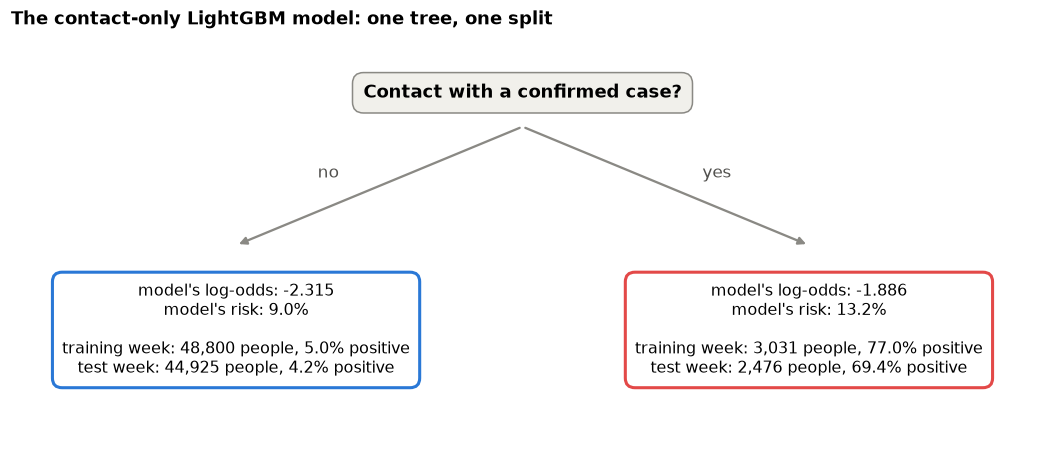

In [12]:
def draw_split(ax, question, branches, title):
    # A one-split tree: root box, two leaves, and annotations per leaf
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    box = dict(boxstyle="round,pad=0.6", facecolor="#f1f0eb", edgecolor=GREY)
    ax.text(0.5, 0.86, question, ha="center", va="center", fontsize=12, fontweight="bold", bbox=box)
    for x, (answer, lines, color) in zip((0.22, 0.78), branches):
        ax.annotate("", xy=(x, 0.5), xytext=(0.5, 0.78), arrowprops=dict(arrowstyle="-|>", color=GREY, linewidth=1.5))
        ax.text((x + 0.5) / 2 + (-0.05 if x < 0.5 else 0.05), 0.66, answer, ha="center", fontsize=11, color="#52514e")
        ax.text(x, 0.3, "\n".join(lines), ha="center", va="center", fontsize=10.5,
                bbox=dict(boxstyle="round,pad=0.6", facecolor="white", edgecolor=color, linewidth=2))
    ax.set_title(title, loc="left")

leaf = {}
for c in (0, 1):
    raw = booster.predict(pd.DataFrame({"contact": [float(c)]}), raw_score=True, num_iteration=contact_model.n_trees_[0])[0]
    grp_tr, grp_te = train[train.contact == c], test[test.contact == c]
    leaf[c] = [f"model's log-odds: {raw:.3f}", f"model's risk: {1 / (1 + np.exp(-raw)):.1%}", "",
               f"training week: {len(grp_tr):,} people, {grp_tr.y.mean():.1%} positive",
               f"test week: {len(grp_te):,} people, {grp_te.y.mean():.1%} positive"]

fig, ax = plt.subplots(figsize=(12, 5))
draw_split(ax, "Contact with a confirmed case?", [("no", leaf[0], BLUE), ("yes", leaf[1], RED)],
           "The contact-only LightGBM model: one tree, one split")
plt.show()

## 2.1 Right order, wrong probabilities

The model says **13%** risk for contacts when about **70%** of them tested positive. LightGBM starts every prediction from the overall average and moves it a small step per tree (learning rate 0.05). With only one tree, it never gets far from the average.

auROC doesn't notice, because it only measures order, and "contact above no contact" is right. A plain decision tree, which predicts each leaf's actual training rate, ranks people identically and so has **exactly the same auROC**. But its probabilities are honest:

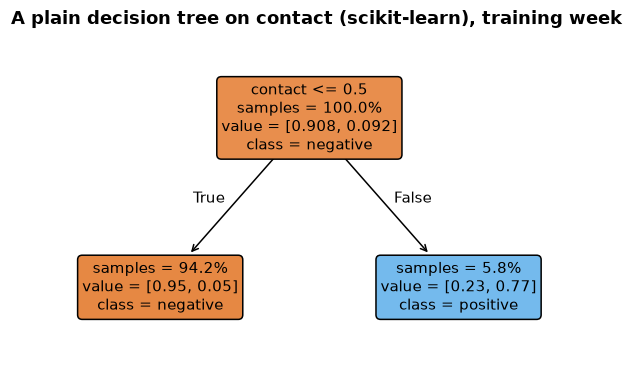

,auROC,Brier score (lower = better calibrated),mean predicted risk,risk if contact,risk if no contact
LightGBM (1 tree),0.729,0.068,0.092,0.132,0.090
decision tree,0.729,0.050,0.088,0.770,0.050


In [13]:
tree = DecisionTreeClassifier(max_depth=1).fit(train[["contact"]], train.y)
fig, ax = plt.subplots(figsize=(7, 4))
plot_tree(tree, feature_names=["contact"], class_names=["negative", "positive"], filled=True, impurity=False,
          proportion=True, rounded=True, fontsize=10, ax=ax)
ax.set_title("A plain decision tree on contact (scikit-learn), training week", loc="left")
plt.show()

p_lgb = contact_model.predict(test)
p_tree = tree.predict_proba(test[["contact"]])[:, 1]
pd.DataFrame({
    "LightGBM (1 tree)": {**{k: v for k, v in sp.metrics(test.y, p_lgb).items() if k in ("auroc", "brier", "mean_predicted")},
                          "risk if contact": p_lgb[test.contact == 1][0], "risk if no contact": p_lgb[test.contact == 0][0]},
    "decision tree": {**{k: v for k, v in sp.metrics(test.y, p_tree).items() if k in ("auroc", "brier", "mean_predicted")},
                      "risk if contact": p_tree[test.contact == 1][0], "risk if no contact": p_tree[test.contact == 0][0]},
}).T.rename(columns={"auroc": "auROC", "brier": "Brier score (lower = better calibrated)", "mean_predicted": "mean predicted risk"})\
    .style.format("{:.3f}")

(In the tree diagram, `value` is the share of negatives and positives in each leaf. The right-hand leaf is the 77% positive rate among contacts in the training week.)

**Why this matters for choosing a threshold:** auROC can't tell these two models apart, but a rule like "refer anyone with risk above 8%" would refer *everyone* using the LightGBM model (it gives 9.0% and 13.2%), and only contacts using the decision tree (5.0% and 77.0%). Before setting a probability threshold, check calibration: compare the mean predicted risk with the actual rate, as the Brier score and the "mean predicted risk" column do above.

---
# 3. The three LightGBMs in `alternative-modelling.ipynb`

The leaderboard has three LightGBM entries. They're the same *kind* of model and differ in two things: the **recipe** (hyperparameters) and **who trained it, on what**.

| | Recipe (hyperparameters) | Who trained it | Training data | How the number of trees was chosen |
|---|---|---|---|---|
| **LightGBM (paper)** | the paper's | us, in `symptompred` | our split (unknown sex dropped): 80% to fit, 20% held out for early stopping | early stopping on the 20%, patience 50 |
| **Tuned LightGBM (saved file)** | the groupmate's (found by Optuna) | the groupmate | their split (unknown sex kept): picked the number of trees on a held-out fold, then refit on **all** training rows | early stopping (patience 30), then a refit with that many trees |
| **LightGBM (tuned params)** | the groupmate's (copied exactly) | us, in `symptompred` | our split: 80% to fit, 20% held out | early stopping on the 20%, patience 30 |

So "tuned params" is **the groupmate's recipe, cooked again in our kitchen**. It exists because the saved file is fixed: it was trained on exactly 8 features from Israel, so it can't be retrained without the biased symptoms (section 6) or on other countries (section 7). To use the groupmate's settings in those experiments, the recipe had to be retrained with `symptompred`. It's labelled a *reference*, not a contender, because it's their tuning, not an alternative technique.

In [14]:
import lightgbm as lgb
from pathlib import Path

TUNED_FILE = Path("benchmarks/lgbm_tuned_model.txt")   # see benchmarks/README.md to fetch it
models = {"LightGBM (paper)": sp.SymptomModel().fit(train),
          "LightGBM (tuned params)": sp.registry()["LightGBM (tuned params)"]().fit(train)}

settings = ["num_leaves", "min_data_in_leaf", "feature_fraction", "bagging_fraction", "bagging_freq", "learning_rate",
            "lambda_l1", "lambda_l2"]
table = pd.DataFrame({
    "LightGBM (paper)": {k: sp.PAPER_PARAMS.get(k, 0) for k in settings},
    "Tuned LightGBM (saved file)": {k: sp.TUNED_PARAMS[k] for k in settings},
    "LightGBM (tuned params)": {k: sp.TUNED_PARAMS[k] for k in settings},
}).astype(object)
table.loc["trees"] = [models["LightGBM (paper)"].n_trees_[0], np.nan, models["LightGBM (tuned params)"].n_trees_[0]]
scores = {name: m.predict(test) for name, m in models.items()}
if TUNED_FILE.exists():
    booster = lgb.Booster(model_file=str(TUNED_FILE))
    columns = ["male", "age_60", "cough", "fever", "sore_throat", "shortness_of_breath", "headache", "contact"]  # its feature order
    scores["Tuned LightGBM (saved file)"] = booster.predict(test[columns])
    table.loc["trees", "Tuned LightGBM (saved file)"] = booster.num_trees()
else:
    print(f"{TUNED_FILE} not found: see benchmarks/README.md. Showing the two retrainable models only.")
for name, p in scores.items():
    m = sp.metrics(test.y, p)
    table.loc["test auROC", name], table.loc["test auPRC", name] = round(m["auroc"], 4), round(m["auprc"], 4)
table.index.name = "setting"
table.map(lambda v: f"{v:g}" if isinstance(v, (int, float, np.number)) else v)

,LightGBM (paper),Tuned LightGBM (saved file),LightGBM (tuned params)
setting,,,
num_leaves,20,7,7
min_data_in_leaf,4,59,59
feature_fraction,0.2,0.715445,0.715445
bagging_fraction,0.8,0.971699,0.971699
bagging_freq,5,4,4
learning_rate,0.05,0.142884,0.142884
lambda_l1,0,0.238361,0.238361
lambda_l2,0,0.0890232,0.0890232
trees,195,24,54


**Reading the table**

- **Paper vs the two tuned models: the recipe matters.** The groupmate's search moved to fewer, smaller trees with more regularisation (`num_leaves` 7, `min_data_in_leaf` 59, L1/L2 penalties) and a faster learning rate. Above all, it raised `feature_fraction` from 0.2 to 0.72, so each tree sees most of the features and can learn combinations of answers. That's worth about +0.0025 auROC and +0.03–0.04 auPRC, taking the model to the ceiling.
- **Saved file vs tuned params: same recipe, different training run.** They differ only in *how* they were trained. One was refit on all training rows, including people with unknown sex; the other was fit on 80% with a 20% early-stopping hold-out, with unknown sex dropped. Early stopping on a different hold-out picked a different number of trees (54 here, 24 in the file), and the predictions differ slightly. Their auROC is identical to 3 decimal places, but the retrained one scores about 0.009 higher auPRC.

That second point is the useful one to remember. **An auPRC difference of about 0.01 can come from training details alone, with no change of technique or settings.** That's why `alternative-modelling.ipynb` treats the alternatives' auPRC edge over the saved file (+0.003 to +0.008) as "matching", not "beating".

---
# 4. How the datasets differ, and how confident would we be deploying the paper's model?

The paper reports auROC 0.90 and suggests the model could help "prioritize testing for COVID-19 when testing resources are limited". Before trusting that, it's worth asking how the Israeli data was collected, how it differs from the US and Brazilian data, and what happens to the model in situations it would meet if deployed.

**Short answer:** we'd have **low confidence** deploying the published model anywhere except the setting it came from, and only moderate confidence even there. The 0.90 depends on how Israel recorded its data in spring 2020: symptoms checked more thoroughly *after* a positive result, and a "contact" flag that comes from the contact-tracing system. In realistic deployments we'd expect roughly 0.6–0.85, with probabilities that need recalibrating. The rest of this section shows where each part of that comes from.

In [15]:
datasets = {"Israel": israel, "US (Carbon Health)": sp.datasets.carbon_health.load()}
if sp.datasets.brazil.available():
    datasets["Brazil (Acre)"] = sp.datasets.brazil.load()
else:
    print("Brazil data not downloaded (see README): Brazil is left out of this section.")
SYMPTOMS = ["cough", "fever", "sore_throat", "shortness_of_breath", "headache"]

overview = {}
for name, df in datasets.items():
    pos = df[df.y == 1]
    overview[name] = {
        "tests": f"{len(df):,}",
        "period": f"{df.date.min():%b %Y} – {df.date.max():%b %Y}",
        "positive rate": f"{df.y.mean():.1%}",
        "features collected": len(sp.available_features(df)),
        "positives reporting none of the 5 symptoms": f"{(pos[SYMPTOMS].fillna(0).sum(axis=1) == 0).mean():.0%}",
    }
pd.DataFrame(overview)

,Israel,US (Carbon Health),Brazil (Acre)
tests,"255,911","93,995","98,095"
period,Mar 2020 – Apr 2020,Apr 2020 – Oct 2020,Mar 2020 – Dec 2022
positive rate,5.3%,1.4%,43.1%
features collected,8,13,10
positives reporting none of the 5 symptoms,36%,52%,7%


| | Israel (the paper) | US (Carbon Health) | Brazil (Acre) |
|---|---|---|---|
| **Who was tested** | early 2020 policy: contacts of cases, returning travellers, people with symptoms | walk-in clinics, later pop-ups and home kits (screening the mostly healthy) | people notified with flu-like illness (nearly everyone is ill) |
| **When symptoms were recorded** | at testing, but **completed and checked afterwards for positives** by epidemiological investigation | at the visit, **before** the result | at notification, **before** or alongside the result |
| **What "contact" means** | the official *reason for the test*: sent by contact tracing | self-reported "may have been exposed" | not collected |
| **Sex** | recorded | not collected | recorded |
| **Extra symptoms** (smell, taste, ...) | not collected | 6 extra | 3 extra |

## 4.1 Was the result known when the symptoms were written down?

Not before the test was taken, but for many positives the symptoms were **completed after the result was known**. The paper says so itself:

> "symptom reporting was more comprehensive among those who tested positive for COVID-19, and validated with a directed epidemiological effort. Thus, mislabeling of symptoms among those who tested negative for COVID-19 is expected."

A positive result triggered an epidemiological investigation, which filled in and checked that person's symptoms. Negatives had no such follow-up, so their symptoms were more often left as "no". The result therefore leaks into the symptom columns. A deployed triage tool asks its questions *before* anyone has a result, so it can never benefit from that leak.

The fingerprint of the leak: among people recorded with a symptom, what share tested positive? In Israel, nearly everyone recorded with headache, sore throat or shortness of breath was positive. In the other two countries, where symptoms were recorded before the result, the same symptoms carry far less signal.

Share positive among people recorded with each feature


,Israel,US (Carbon Health),Brazil (Acre)
cough,16%,7%,49%
fever,25%,11%,50%
sore_throat,91%,3%,44%
shortness_of_breath,91%,4%,47%
headache,95%,5%,42%
contact,71%,1%,not collected
loss_of_smell,not collected,24%,70%
(overall positive rate),5%,1%,43%


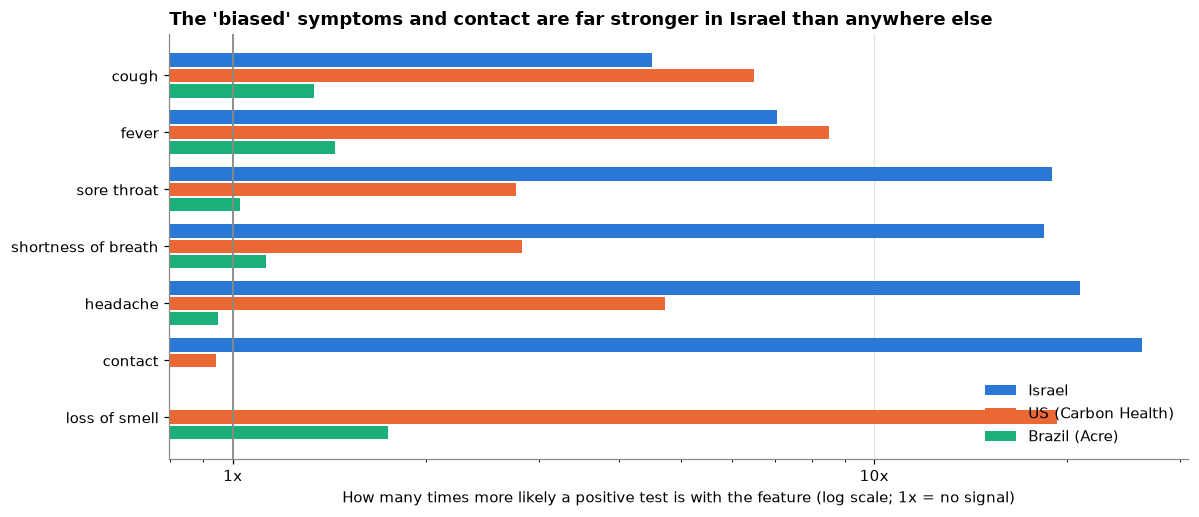

In [16]:
def lift(df, f):
    # How many times more likely a positive test is with the feature than without it (1 = no signal)
    return df.loc[df[f] == 1, "y"].mean() / df.loc[df[f] == 0, "y"].mean()

feats = SYMPTOMS + ["contact", "loss_of_smell"]
share_pos = pd.DataFrame({name: {f: df.loc[df[f] == 1, "y"].mean() if f in df else np.nan for f in feats}
                          | {"(overall positive rate)": df.y.mean()} for name, df in datasets.items()})
lifts = pd.DataFrame({name: {f: lift(df, f) if f in df else np.nan for f in feats} for name, df in datasets.items()})
print("Share positive among people recorded with each feature")
display(share_pos.style.format("{:.0%}", na_rep="not collected"))

colors = {"Israel": BLUE, "US (Carbon Health)": ORANGE, "Brazil (Acre)": AQUA}
fig, ax = plt.subplots(figsize=(11, 4.8))
width = 0.8 / len(datasets)
for j, name in enumerate(datasets):
    ax.barh(np.arange(len(feats)) + (j - (len(datasets) - 1) / 2) * width, lifts[name], height=width * 0.9,
            color=colors[name], label=name)
ax.set_xscale("log")
ax.axvline(1, color=GREY, linewidth=1.2)
ax.set_yticks(range(len(feats)), [f.replace("_", " ") for f in feats])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}x"))
ax.set_xlabel("How many times more likely a positive test is with the feature (log scale; 1x = no signal)")
ax.set_title("The 'biased' symptoms and contact are far stronger in Israel than anywhere else", loc="left")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

- **Headache, sore throat, shortness of breath:** about 18–21x in Israel, against about 3–5x in the US and about 1x in Brazil. Their strength in Israel is mostly the recording leak.
- **Cough and fever** (the paper's "balanced" symptoms) stay useful in Israel and the US. In Brazil, where everyone tested is already ill, nothing separates COVID from other respiratory infections much.
- **Loss of smell**, which Israel didn't collect, is the strongest symptom wherever it exists.

## 4.2 "Contact" isn't a symptom

Israel's `contact` comes from `test_indication`: the official reason the person was tested. A value of "contact with a confirmed case" means the **contact-tracing system sent them**. It's the single strongest feature (about 26x). Removing it costs Israel 0.10 auROC (`alternative-data` 4.6). In the US the nearest equivalent, a self-reported "may have been exposed", carries no signal (about 0.9x), and Brazil doesn't record it. The model only gets this information where an effective contact-tracing system feeds it in.

## 4.3 Other inconsistencies between the datasets

In [17]:
us = datasets["US (Carbon Health)"]
us_train, us_test = sp.date_split(us, ("2020-04-01", "2020-08-31"), ("2020-09-01", "2020-10-31"))
print("US: a blank 'fever' field changed meaning between periods")
for period, df in [("Apr–Aug", us_train), ("Sep–Oct", us_test)]:
    blank = df.fever.isna()
    print(f"  {period}: {blank.mean():.0%} blank; positive rate {df[blank].y.mean():.2%} if blank vs {df[~blank].y.mean():.2%} if recorded")

weekly = israel.assign(week=israel.date.dt.to_period("W").dt.start_time).groupby("week").agg(
    tests=("y", "size"), positive_rate=("y", "mean"), contact_share=("contact", "mean"),
    age_missing=("age_60", lambda s: s.isna().mean()))
weekly.index = [f"week of {d:%d %b}" for d in weekly.index]
print("\nIsrael, week by week (the paper trains on 22–31 Mar and tests on 1–7 Apr)")
display(weekly.style.format({"tests": "{:,}", "positive_rate": "{:.1%}", "contact_share": "{:.1%}", "age_missing": "{:.0%}"}))

if "Brazil (Acre)" in datasets:
    br = datasets["Brazil (Acre)"]
    by_year = br.assign(year=br.date.dt.year).groupby("year").agg(tests=("y", "size"), positive_rate=("y", "mean"),
                                                                 loss_of_smell=("loss_of_smell", "mean"))
    print("Brazil, by year (the 2022 test year is the Omicron period)")
    display(by_year.style.format({"tests": "{:,}", "positive_rate": "{:.1%}", "loss_of_smell": "{:.1%}"}))

US: a blank 'fever' field changed meaning between periods
  Apr–Aug: 8% blank; positive rate 4.60% if blank vs 1.95% if recorded
  Sep–Oct: 39% blank; positive rate 0.23% if blank vs 1.02% if recorded

Israel, week by week (the paper trains on 22–31 Mar and tests on 1–7 Apr)


,tests,positive_rate,contact_share,age_missing
week of 16 Mar,"3,470",7.8%,3.6%,0%
week of 23 Mar,"35,560",8.9%,5.8%,0%
week of 30 Mar,"49,192",8.3%,5.2%,0%
week of 06 Apr,"34,326",6.9%,6.2%,0%
week of 13 Apr,"53,329",3.7%,2.9%,74%
week of 20 Apr,"55,353",2.3%,1.6%,100%
week of 27 Apr,"24,681",1.9%,1.2%,100%


Brazil, by year (the 2022 test year is the Omicron period)


,tests,positive_rate,loss_of_smell
year,,,
2020,"38,477",46.3%,7.4%
2021,"51,275",40.0%,14.8%
2022,"8,343",47.0%,2.3%


| Issue | What we found | Why it matters for deployment |
|---|---|---|
| **Different questions** | No dataset has all the features: the US lacks sex, Brazil lacks contact, Israel lacks loss of smell and taste | A model can only be moved where the same questions are asked. Across all three, the shared set is just the 5 symptoms and age |
| **Same name, different meaning** | "Contact" is a tracing referral in Israel and a self-reported worry in the US | The feature's strength doesn't transfer, and can even reverse |
| **Blanks change meaning** | In the US, a blank fever field meant *higher* risk in spring and *lower* in autumn, as testing moved to pop-ups and home kits | A model that learns from blanks learns the testing setting, not the patient, and that setting changes |
| **Fields stop being recorded** | Israel stopped recording age from mid-April 2020 (the table above) | A deployed model must cope with missing inputs it never saw in training |
| **Who gets tested changes** | Israel's positive rate fell from about 9% to 2% in five weeks as testing widened; the US moved from clinics to screening | Both the model's ranking and its probabilities drift (4.4) |
| **The virus changes** | Loss of smell fell from about 15% of Brazilian tests in 2021 to about 2% in 2022 (Omicron) | Symptom profiles drift with variants, so a model needs retraining |
| **Data quality** | US: only the week of each test is known, and ages are noise-added for privacy. Brazil: about 98% from one state (Acre), ages capped in the mid-50s | Limits what can be checked, and how far the results generalise |

## 4.4 Stress-testing the paper's model

The paper's method (`sp.SymptomModel()`, trained on the paper's training window) in the situations a deployment would meet:

In [18]:
B = ["sore_throat", "shortness_of_breath", "headache"]
paper_model = sp.SymptomModel().fit(train)
threshold = sp.working_point(test.y.values, paper_model.predict(test), 0.873)["threshold"]   # the paper's working point

print("1. The same model in later weeks in Israel (threshold fixed at the paper's 87% sensitivity point)")
rows = []
for lo, hi in [("2020-04-01", "2020-04-07"), ("2020-04-08", "2020-04-14"), ("2020-04-15", "2020-04-21"), ("2020-04-22", "2020-04-30")]:
    w = israel[israel.date.between(lo, hi)]
    p = paper_model.predict(w)
    flagged, positive = p >= threshold, w.y.values == 1
    rows.append({"week": f"{pd.Timestamp(lo):%d %b}–{pd.Timestamp(hi):%d %b}" + (" (paper's test week)" if lo == "2020-04-01" else ""),
                 "positive rate": w.y.mean(), "auROC": sp.metrics(w.y, p)["auroc"],
                 "mean predicted risk": p.mean(),
                 "sensitivity at the fixed threshold": (flagged & positive).sum() / positive.sum(),
                 "share of people flagged": flagged.mean()})
ageing = pd.DataFrame(rows).set_index("week")
display(ageing.style.format("{:.3f}", subset=["auROC"]).format("{:.1%}", subset=["positive rate", "mean predicted risk",
        "sensitivity at the fixed threshold", "share of people flagged"]))

1. The same model in later weeks in Israel (threshold fixed at the paper's 87% sensitivity point)


,positive rate,auROC,mean predicted risk,sensitivity at the fixed threshold,share of people flagged
week,,,,,
01 Apr–07 Apr (paper's test week),7.6%,0.902,8.0%,87.3%,32.5%
08 Apr–14 Apr,6.1%,0.835,8.5%,84.7%,50.8%
15 Apr–21 Apr,2.8%,0.848,4.8%,74.2%,17.4%
22 Apr–30 Apr,2.1%,0.818,3.9%,66.4%,11.9%


In [19]:
print("2. Without the parts specific to how Israel recorded its data (paper's split)")
scenarios = {}
for label, feats in {"as published (all 8 features)": F,
                     "symptoms asked before the result (no biased trio)": [f for f in F if f not in B],
                     "no contact-tracing system (no contact)": [f for f in F if f != "contact"],
                     "neither": [f for f in F if f not in B + ["contact"]]}.items():
    scenarios[f"Israel: {label}"] = sp.SymptomModel(features=feats).fit(train).evaluate(test, bootstrap=0)["auroc"]

print("3. Taken to another country as-is, or retrained there")
calibration = {}
others = {"US (Carbon Health)": (us_train, us_test)}
if "Brazil (Acre)" in datasets:
    others["Brazil (Acre)"] = sp.date_split(datasets["Brazil (Acre)"], ("2020-01-01", "2021-12-31"), ("2022-01-01", "2022-12-31"))
for name, (o_train, o_test) in others.items():
    shared = sp.common_features(train, o_test, candidates=sp.CORE_FEATURES)
    r = sp.SymptomModel(features=shared, n_models=5).fit(train).evaluate(o_test, bootstrap=0)
    scenarios[f"{name}: Israeli model used as-is"] = r["auroc"]
    calibration[name] = {"Israeli model's mean predicted risk": r["mean_predicted"], "actual positive rate": r["prevalence"]}
    scenarios[f"{name}: retrained locally, paper's settings"] = sp.SymptomModel(features="core", n_models=5).fit(o_train).evaluate(o_test, bootstrap=0)["auroc"]
    scenarios[f"{name}: retrained locally, best settings"] = sp.SymptomModel(features="all", missing="absent", n_models=5).fit(o_train).evaluate(o_test, bootstrap=0)["auroc"]
scenarios = pd.Series(scenarios, name="auROC")
display(scenarios.to_frame().style.format("{:.3f}"))
print("Calibration when the Israeli model is used as-is:")
display(pd.DataFrame(calibration).T.style.format("{:.1%}"))

2. Without the parts specific to how Israel recorded its data (paper's split)


3. Taken to another country as-is, or retrained there


,auROC
Israel: as published (all 8 features),0.902
Israel: symptoms asked before the result (no biased trio),0.872
Israel: no contact-tracing system (no contact),0.800
Israel: neither,0.741
US (Carbon Health): Israeli model used as-is,0.595
"US (Carbon Health): retrained locally, paper's settings",0.556
"US (Carbon Health): retrained locally, best settings",0.708
Brazil (Acre): Israeli model used as-is,0.685
"Brazil (Acre): retrained locally, paper's settings",0.641
"Brazil (Acre): retrained locally, best settings",0.636


Calibration when the Israeli model is used as-is:


,Israeli model's mean predicted risk,actual positive rate
US (Carbon Health),10.7%,0.7%
Brazil (Acre),27.7%,47.0%


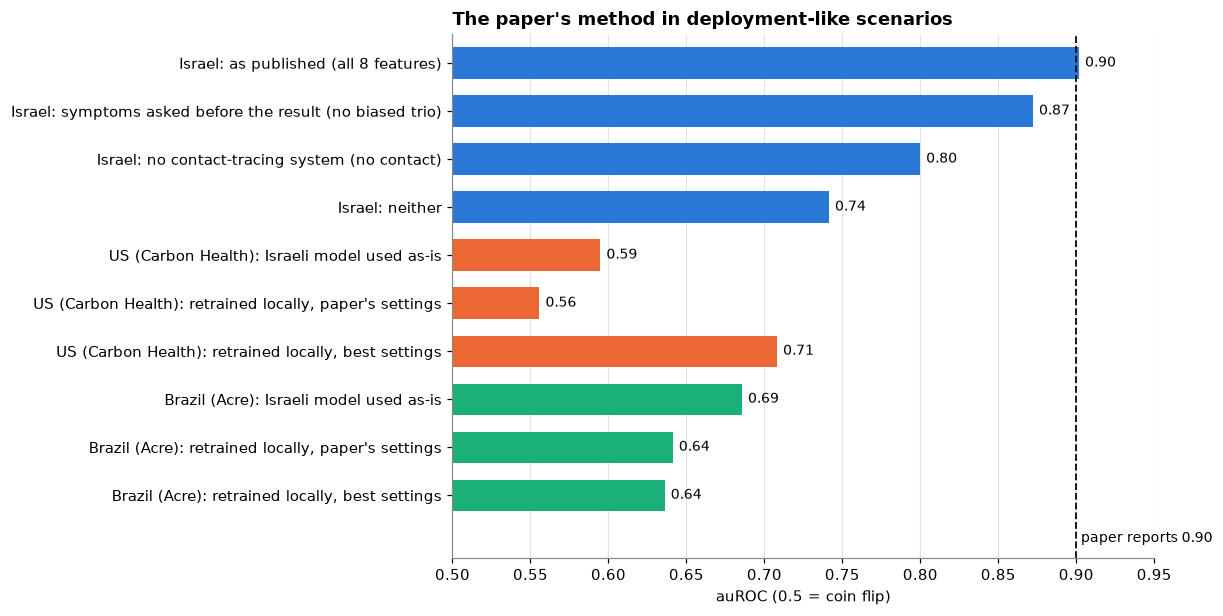

In [20]:
order = list(scenarios.index)
fig, ax = plt.subplots(figsize=(11, 0.42 * len(order) + 1.5))
bar_colors = [BLUE if k.startswith("Israel") else ORANGE if k.startswith("US") else AQUA for k in order]
ax.barh(range(len(order)), scenarios.values - 0.5, left=0.5, color=bar_colors, height=0.65)
for i, v in enumerate(scenarios.values):
    ax.text(v + 0.004, i, f"{v:.2f}", va="center", fontsize=9)
ax.axvline(0.90, color=INK, linestyle="--", linewidth=1.2)
ax.set_ylim(len(order) + 0.3, -0.6)
ax.text(0.903, len(order) - 0.1, "paper reports 0.90", ha="left", va="center", fontsize=9)
ax.set_yticks(range(len(order)), order)
ax.set_xlim(0.5, 0.95)
ax.set_xlabel("auROC (0.5 = coin flip)")
ax.set_title("The paper's method in deployment-like scenarios", loc="left")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**What the stress tests show**

1. **It ages within weeks, even in Israel.** One week after the test week, auROC falls from 0.90 to about 0.84 and stays there. Worse, the threshold that gave 87% sensitivity flags half of everyone the next week. By late April it catches only about two-thirds of positives, because the tested population (and the positive rate) changed underneath it. A deployed model would need its threshold and calibration monitored and updated week by week.
2. **Asking symptoms before the result costs 0.03; losing contact tracing costs 0.10.** Without both, the model scores about 0.74, the same range as the other countries.
3. **It doesn't travel.** Used as-is in the US it scores about 0.60, and predicts an average risk of about 11% where 0.7% actually tested positive, so its probabilities are meaningless there. In Brazil it ranks reasonably (about 0.69) but predicts about 28% risk where 47% were positive.
4. **Retraining locally isn't a simple fix.** With the paper's settings it scores *lower* than the Israeli model used as-is in both countries (US 0.56, Brazil 0.64). In the US, settings adapted to its data (treating blanks as "not reported", adding loss of smell and taste) reach 0.71. In Brazil, nothing trained on 2020–21 local data beats about 0.64 in 2022, because the virus changed (4.3). About 0.64–0.71 is the realistic level for symptom questions asked before the result.

## 4.5 Verdict: how confident would we be?

| Deployment scenario | Expected auROC | Confidence | What it would take |
|---|---|---|---|
| Israel, spring 2020, same data pipeline (contact tracing feeding "contact", symptoms checked after positives) | about 0.90 on the week after training, falling to about 0.84 | **moderate**, for days to weeks | the 0.90 relies on information a real triage tool wouldn't have at the time of asking; weekly monitoring and recalibration |
| Israel, symptoms asked up front, as a real triage tool would | about 0.87 with contact tracing, about 0.74 without | **moderate to low** | prospective validation on data collected before results are known |
| Another country, the published model as-is | about 0.60–0.69, probabilities badly wrong | **low: don't** | |
| Another country, retrained on local data | about 0.56–0.71, depending on how well the method is adapted to local data | **low to moderate** | local data with symptoms recorded before the result; adapting to how fields are recorded there; local validation and threshold choice; retraining as variants and testing policy change |

**Bottom line:** the paper's method is reproducible and its 0.90 is real *for that dataset*. But the number mostly measures how Israel's 2020 data was recorded (contact tracing, and symptoms completed after positive results), not how well symptoms predict COVID. We wouldn't deploy the published model as-is. A symptom-based triage tool is plausible as one input among others, but only if it's:
- built on local data collected **before** results are known;
- validated prospectively;
- given a threshold chosen for the local costs of missed cases and unnecessary referrals;
- monitored, and retrained as the population and the virus change.